# Benchmark: do var2fold's scores separate pathogenic from benign variants?

A tool that links variants to regulation and structure is only useful if those signals carry information. This notebook tests that against ClinVar's expert classifications.

**Data.** [`examples/clinvar_missense_benchmark.vcf`](../examples/clinvar_missense_benchmark.vcf): 300 missense variants in six clinically actionable genes (BRCA1, BRCA2, TP53, MSH2, MLH1, PTEN), 25 Pathogenic/Likely pathogenic and 25 Benign/Likely benign per gene, chosen by ClinVar review status (most are *reviewed by expert panel*, i.e. ClinGen VCEP calls). The file is fixed and dated, so the benchmark does not drift as ClinVar updates.

**Features.** For each variant the full pipeline gives:

| Feature | Source | Expected direction |
|---|---|---|
| pLDDT at the mutated residue | AlphaFold DB | higher (ordered region) → pathogenic |
| \|splicing effect\| | AlphaGenome | larger → pathogenic |
| \|expression effect\| (RNA-seq gene LFC) | AlphaGenome | larger → pathogenic |
| \|accessibility effect\| (DNase/ATAC) | AlphaGenome | larger → pathogenic |
| gnomAD allele frequency | Ensembl VEP | lower → pathogenic (**reference only**) |

**Metric.** ROC AUC (0.5 = chance, 1 = perfect), with a 95% bootstrap CI and a Mann-Whitney p-value. AlphaGenome scores use a 1 Mb window in transverse colon tissue.

> **Circularity.** ClinVar classifiers use population frequency (ACMG criteria BA1/BS1/PM2), so gnomAD's AUC is inflated by construction and is shown only as a ceiling. They may also use computational predictors (PP3/BP4), but neither AlphaFold pLDDT nor AlphaGenome is among the standard ones.

In [1]:
import logging
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from var2fold.config import Settings
from var2fold.pipeline import GenomeToStructurePipeline, batch_table
from var2fold.plots import style
from var2fold.validation import (
    DEFAULT_FEATURES,
    auc_by_group,
    evaluate_features,
    oriented,
    roc_auc,
    roc_points,
    vcf_clinvar_labels,
)

logging.basicConfig(level=logging.WARNING)
warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
os.chdir(ROOT)  # .env, .cache/ and data/ are resolved from the project root
VCF = ROOT / "examples" / "clinvar_missense_benchmark.vcf"
COLON = "UBERON:0001157"  # transverse colon
FIG_DIR = ROOT / "docs" / "img"

pipeline = GenomeToStructurePipeline(Settings.from_env(), sequence_length=1_048_576)

## 1. Score the benchmark set

One call runs the whole pipeline; labels come from INFO/CLNSIG in the VCF.

In [2]:
results = pipeline.run_vcf(VCF, conditions=[COLON], max_variants=None)
labels = vcf_clinvar_labels(VCF)
table = batch_table(results).drop(columns=["vcf_id"]).merge(labels, on="variant", how="inner")
failed = table["warnings"].fillna("").str.contains("failed")
table = table[~failed & table["label"].notna()].copy()
table["label"] = table["label"].astype(int)
table["class"] = table["label"].map({1: "pathogenic", 0: "benign"})
print(f"{len(table)} of {len(labels)} variants scored ({int(failed.sum())} failed)")
pd.crosstab(table["gene"], table["class"], margins=True)

300 of 300 variants scored (0 failed)


class,benign,pathogenic,All
gene,,,
BRCA1,25,25,50
BRCA2,25,25,50
MLH1,25,25,50
MSH2,25,25,50
PTEN,25,25,50
TP53,25,25,50
All,150,150,300


Review status of the selected variants (ClinVar stars):

In [3]:
pd.crosstab(table["review_status"], table["class"])

class,benign,pathogenic
review_status,,
"criteria provided, multiple submitters, no conflicts",7,0
"criteria provided, single submitter",12,0
reviewed by expert panel,131,150


## 2. Overall discrimination

In [4]:
summary = evaluate_features(table, DEFAULT_FEATURES, n_boot=2000, seed=0)
summary

,feature,description,n_pathogenic,n_benign,auc,ci_low,ci_high,p_value
0,residue_plddt,AlphaFold pLDDT at the mutated residue,123,110,0.821,0.765,0.873,2.973e-17
1,splicing,AlphaGenome |splicing effect|,150,150,0.674,0.613,0.731,1.770e-07
2,rna_lfc,AlphaGenome |expression effect| (RNA-seq gene ...,150,150,0.512,0.444,0.574,7.178e-01
3,accessibility,AlphaGenome |accessibility effect| (DNase/ATAC),150,150,0.475,0.409,0.542,4.508e-01
4,gnomad_af,gnomAD allele frequency (reference only: ClinV...,150,150,0.893,0.855,0.930,8.693e-35


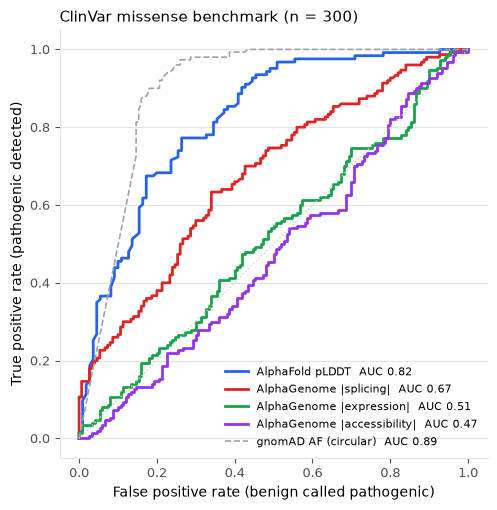

In [5]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
colors = {"residue_plddt": "#2563eb", "splicing": "#dc2626", "rna_lfc": "#16a34a",
          "accessibility": "#9333ea", "gnomad_af": "#9ca3af"}
names = {"residue_plddt": "AlphaFold pLDDT", "splicing": "AlphaGenome |splicing|",
         "rna_lfc": "AlphaGenome |expression|", "accessibility": "AlphaGenome |accessibility|",
         "gnomad_af": "gnomAD AF (circular)"}
for f in DEFAULT_FEATURES:
    s = oriented(f, table)
    keep = s.notna()
    fpr, tpr = roc_points(s[keep], table.loc[keep, "label"])
    auc = summary.set_index("feature").loc[f.column, "auc"]
    ax.plot(fpr, tpr, color=colors[f.column], lw=2 if f.column != "gnomad_af" else 1.2,
            ls="-" if f.column != "gnomad_af" else "--", label=f"{names[f.column]}  AUC {auc:.2f}")
ax.plot([0, 1], [0, 1], color="#d1d5db", lw=1, ls=":")
ax.set_xlabel("False positive rate (benign called pathogenic)")
ax.set_ylabel("True positive rate (pathogenic detected)")
ax.set_title(f"ClinVar missense benchmark (n = {len(table)})", loc="left", fontsize=11)
ax.legend(loc="lower right", fontsize=8, frameon=False)
ax.set_aspect("equal")
style(ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "benchmark_roc.png", dpi=150)
plt.show()

## 3. Per gene

AUC of each feature within each gene (25 vs 25 variants, so each value has a wide CI, roughly ±0.15).

In [6]:
per_gene = auc_by_group(table, "gene", DEFAULT_FEATURES)
per_gene.style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=0, vmax=1)

,residue_plddt,splicing,rna_lfc,accessibility,gnomad_af
BRCA1,0.89,0.70,0.43,0.39,0.95
BRCA2,nan,0.87,0.69,0.61,0.94
MLH1,0.69,0.59,0.56,0.39,0.90
MSH2,0.83,0.55,0.47,0.45,0.92
PTEN,0.81,0.75,0.39,0.48,0.78
TP53,0.84,0.62,0.53,0.57,0.86


## 4. Structure: where do pathogenic and benign variants sit on the AlphaFold model?

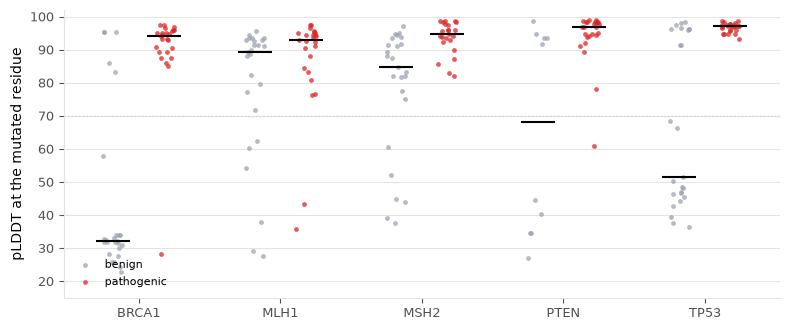

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
# BRCA2 has no AlphaFold DB model, so it has no pLDDT column here
genes = sorted(table.dropna(subset=["residue_plddt"])["gene"].unique())
rng = np.random.default_rng(0)
for i, gene in enumerate(genes):
    for cls, dx, color in (("benign", -0.18, "#9ca3af"), ("pathogenic", 0.18, "#dc2626")):
        v = table.loc[(table["gene"] == gene) & (table["class"] == cls), "residue_plddt"].dropna()
        ax.scatter(i + dx + rng.uniform(-0.07, 0.07, len(v)), v, s=12, color=color, alpha=0.75,
                   label=cls if i == 0 else None, linewidths=0)
        ax.hlines(v.median(), i + dx - 0.12, i + dx + 0.12, color="black", lw=1.5)
ax.axhline(70, color="#d1d5db", lw=1, ls=":")
ax.set_xticks(range(len(genes)), genes)
ax.set_ylabel("pLDDT at the mutated residue")
ax.set_ylim(15, 102)
ax.legend(frameon=False, fontsize=8, loc="lower left")
style(ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "benchmark_plddt.png", dpi=150)
plt.show()

In [8]:
bands = pd.cut(table["residue_plddt"], [0, 50, 70, 90, 100],
               labels=["<50 (disordered)", "50-70", "70-90", ">90 (very high)"])
pd.crosstab(bands, table["class"], margins=True).assign(
    pathogenic_share=lambda d: (d["pathogenic"] / d["All"]).round(2)
)

class,benign,pathogenic,All,pathogenic_share
residue_plddt,,,,
<50 (disordered),42,3,45,0.07
50-70,10,1,11,0.09
70-90,20,19,39,0.49
>90 (very high),38,100,138,0.72
All,110,123,233,0.53


## 5. Splicing: the largest AlphaGenome splicing effects

In [9]:
cols = ["gene", "vcf_id", "class", "consequence", "splicing", "residue_plddt", "clnsig"]
table.assign(abs_splicing=table["splicing"].abs()).nlargest(12, "abs_splicing")[cols]

,gene,vcf_id,class,consequence,splicing,residue_plddt,clnsig
14,BRCA1,D1692H,pathogenic,missense_variant&splice_region_variant,9.625,94.06,Pathogenic
124,TP53,S106R,pathogenic,missense_variant,9.469,97.12,Pathogenic
174,MSH2,V859I,pathogenic,splice_donor_variant,8.898,NaN,Likely pathogenic
16,BRCA1,E1559K,pathogenic,missense_variant&splice_region_variant,8.312,28.28,Pathogenic
71,BRCA2,S3018G,pathogenic,missense_variant,7.441,NaN,Pathogenic
4,BRCA1,D1778N,pathogenic,missense_variant&splice_region_variant,7.270,93.38,Pathogenic
166,MSH2,G669V,pathogenic,splice_donor_variant,7.203,NaN,Likely pathogenic
217,MLH1,Q346R,pathogenic,missense_variant&splice_region_variant,7.059,35.94,Pathogenic
161,MSH2,S554C,pathogenic,missense_variant&splice_region_variant,6.176,89.88,Pathogenic
262,PTEN,L112V,pathogenic,missense_variant,6.102,98.50,Likely pathogenic


How many of the largest splicing scores are pathogenic?

In [10]:
abs_spl = table["splicing"].abs()
ranked = table.assign(abs_splicing=abs_spl).sort_values("abs_splicing", ascending=False)
pd.DataFrame(
    {"top_k": k, "pathogenic": int(ranked["label"].head(k).sum())} for k in (10, 20, 30, 50)
).assign(share=lambda d: (d["pathogenic"] / d["top_k"]).round(2))

,top_k,pathogenic,share
0,10,10,1.00
1,20,19,0.95
2,30,26,0.87
3,50,37,0.74


Is the splicing signal only the variants VEP already flags as splice-related?

In [11]:
splice_term = table["consequence"].fillna("").str.contains("splice")
print(pd.crosstab(splice_term.rename("VEP splice term"), table["class"]))
rest = ~splice_term
print(f"\nAUC of |splicing| without VEP splice-region/donor variants: "
      f"{roc_auc(abs_spl[rest], table.loc[rest, 'label']):.2f} (n = {int(rest.sum())})")

class            benign  pathogenic
VEP splice term                    
False               145         133
True                  5          17

AUC of |splicing| without VEP splice-region/donor variants: 0.64 (n = 278)


## 6. Does splicing explain pathogenic variants that structure misses?

In [12]:
threshold = abs_spl[table["label"] == 0].quantile(0.95)
high_splice = abs_spl > threshold
structure_miss = table["residue_plddt"].isna() | (table["residue_plddt"] < 70)
pathogenic = table["label"] == 1
print(f"|splicing| above the 95th percentile of benign variants ({threshold:.2f}):")
print(f"  benign      {int((~pathogenic & high_splice).sum()):3d} of {int((~pathogenic).sum())}")
print(f"  pathogenic  {int((pathogenic & high_splice).sum()):3d} of {int(pathogenic.sum())}")
print(f"  pathogenic with pLDDT < 70 or no model: "
      f"{int((pathogenic & structure_miss & high_splice).sum())} of "
      f"{int((pathogenic & structure_miss).sum())}")

|splicing| above the 95th percentile of benign variants (0.48):
  benign        8 of 150
  pathogenic   33 of 150
  pathogenic with pLDDT < 70 or no model: 10 of 31


## 7. Which variants have no pLDDT?

In [13]:
missing = table[table["residue_plddt"].isna()]
missing.groupby(["gene", "class", "consequence"]).size().rename("variants").to_frame()

variants
gene  class      consequence                                     
BRCA2 benign     missense_variant                              25
      pathogenic missense_variant                              23
                 missense_variant&splice_region_variant         2
MSH2  pathogenic splice_donor_variant                           2
PTEN  benign     5_prime_UTR_variant                           15

## Conclusions

**Structure separates the classes well.** AlphaFold pLDDT at the mutated residue gives an AUC of **0.82** (95% CI 0.77–0.87; n = 233 with a model). 72% of variants at residues with pLDDT > 90 are pathogenic, against 7% below 50: pathogenic missense variants concentrate in the folded domains, benign ones in disordered linkers. The signal holds within every gene with a model (AUC 0.69 in MLH1 to 0.89 in BRCA1).

**Splicing is weaker on average but very specific at the top.** AlphaGenome's |splicing effect| has an AUC of **0.67** (0.61–0.73), but its largest scores are almost all pathogenic: **10 of the top 10 and 19 of the top 20**. Many sit on the last bases of an exon (VEP *splice_region* / *splice_donor*), such as BRCA1 D1692H, E1559K and D1778N, which ClinVar lists as missense. The signal is not only those: without VEP splice terms the AUC is still 0.64.

**The two signals are complementary.** Of the 31 pathogenic variants that structure cannot explain (pLDDT < 70 or no model), 10 have a splicing score above the 95th percentile of benign variants. These are candidates for a splicing mechanism and the clearest case for linking regulation and structure in one tool. A naive average of the two ranks does not raise the overall AUC, because splicing carries information only in its tail.

**Expression and accessibility carry no signal here** (AUC 0.51 and 0.48, CIs spanning 0.5). This is the expected negative control: for coding missense variants, gene-level expression and local chromatin are not the mechanism.

### Caveats

* **gnomAD is circular** (AUC 0.89): ClinVar uses allele frequency to classify. It is a ceiling, not a competitor.
* **Partial circularity for splicing**: ClinGen expert panels may cite SpliceAI predictions (ACMG PP3/BP7), and AlphaGenome's splicing signal will correlate with SpliceAI's.
* **Missing structures are not random**: BRCA2 (3,418 aa) has no AlphaFold DB model served by the API, and 15 of the 25 PTEN benign "missense" variants lie in the N-terminal extension of the PTEN-L isoform, which is 5′ UTR in the canonical transcript. Both are excluded from the pLDDT AUC.
* **Selection**: variants are ranked by ClinVar review stars, not sampled at random, and benign variants come from fewer expert panels. 300 variants in 6 genes gives wide per-gene intervals.
* **Not a pathogenicity predictor.** pLDDT measures model confidence, not the effect of the substitution. Dedicated predictors (AlphaMissense, REVEL) are the right comparison for a follow-up.